In [1]:
import sys
sys.path.append("..")

import pandas as pd
import mlflow

# Consolidate everything we found across this project
results_summary = pd.DataFrame([
    {"model": "Naive Baseline", "MAE": 1538.08, "RMSE": 1826.26, "notes": "1-step lookback"},
    {"model": "Seasonal Naive", "MAE": 4837.85, "RMSE": 5791.35, "notes": "24-step lookback"},
    {"model": "SARIMA(2,0,1)(1,0,1,24)", "MAE": 3414.86, "RMSE": 4451.12, "notes": "raw series, D=1, single-shot"},
    {"model": "Linear Regression", "MAE": 405.71, "RMSE": 541.09, "notes": "walk-forward avg, 5 folds"},
    {"model": "Random Forest", "MAE": 261.76, "RMSE": 356.21, "notes": "walk-forward avg, 5 folds"},
    {"model": "XGBoost", "MAE": 251.83, "RMSE": 352.06, "notes": "walk-forward avg, 5 folds"},
    {"model": "LSTM", "MAE": 347.32, "RMSE": 440.89, "notes": "48-hour lookback, single split"},
])

results_summary = results_summary.sort_values("MAE").reset_index(drop=True)
print(results_summary)

                     model      MAE     RMSE                           notes
0                  XGBoost   251.83   352.06       walk-forward avg, 5 folds
1            Random Forest   261.76   356.21       walk-forward avg, 5 folds
2                     LSTM   347.32   440.89  48-hour lookback, single split
3        Linear Regression   405.71   541.09       walk-forward avg, 5 folds
4           Naive Baseline  1538.08  1826.26                 1-step lookback
5  SARIMA(2,0,1)(1,0,1,24)  3414.86  4451.12    raw series, D=1, single-shot
6           Seasonal Naive  4837.85  5791.35                24-step lookback


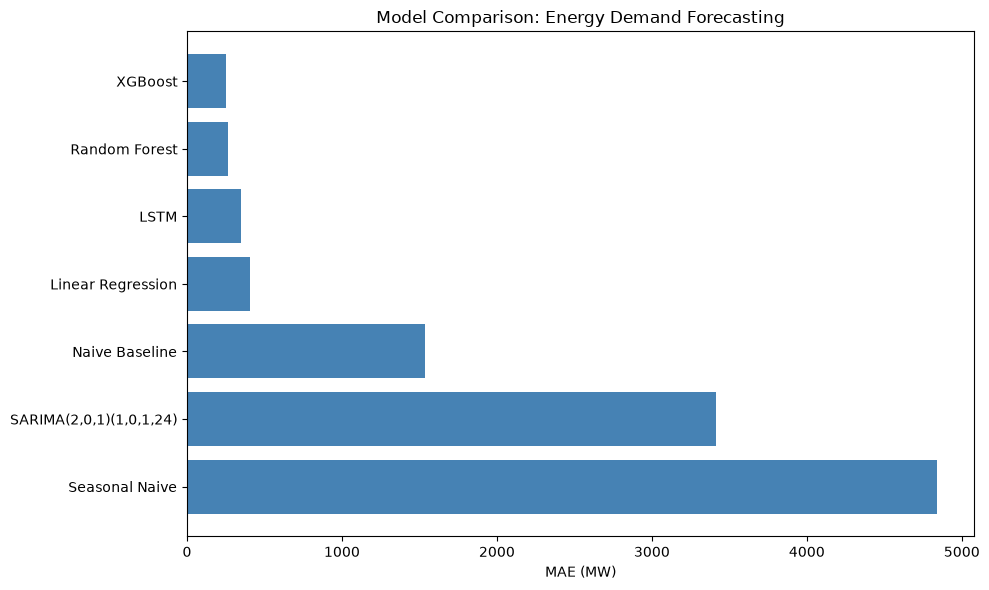

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(results_summary["model"], results_summary["MAE"], color="steelblue")
ax.set_xlabel("MAE (MW)")
ax.set_title("Model Comparison: Energy Demand Forecasting")
ax.invert_yaxis()  # best model at top
plt.tight_layout()
plt.show()

In [8]:
# Build absolute path to project root's mlflow.db, regardless of notebook's cwd

import os


project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))  # adjust ".." if your notebook is deeper
db_path = os.path.join(project_root, "mlflow.db")

mlflow.set_tracking_uri(f"sqlite:///{db_path}")
print("Tracking URI set to:", mlflow.get_tracking_uri())

Tracking URI set to: sqlite:///c:\Users\hp\Desktop\Machine Learning\Energy-Forecast\mlflow.db


In [9]:
mlflow.set_experiment("EnergyForecast")

for _, row in results_summary.iterrows():
    with mlflow.start_run(run_name=row["model"]):
        mlflow.log_param("model_type", row["model"])
        mlflow.log_param("notes", row["notes"])
        mlflow.log_metric("MAE", row["MAE"])
        mlflow.log_metric("RMSE", row["RMSE"])

print("Logged all runs to MLflow")

Logged all runs to MLflow


In [10]:
from src.data_loader import load_pjm_data
from src.features import build_features, FEATURE_COLUMNS
from src.models.ml_models import train_xgboost, save_model

df_full = load_pjm_data("../data/raw/PJME_hourly.csv")
df_full = build_features(df_full).dropna()

X_full = df_full[FEATURE_COLUMNS]
y_full = df_full["PJME_MW"]

final_model = train_xgboost(X_full, y_full)
save_model(final_model, "../models/xgboost_energy_forecast.pkl")

print("Model saved successfully")

Model saved successfully


In [11]:
import requests
import pandas as pd
from src.data_loader import load_pjm_data

df = load_pjm_data("../data/raw/PJME_hourly.csv")

# Grab a 200-hour slice near the end of our data, comfortably more than the 169 minimum
sample = df.iloc[-200:-1]  # leave the very last row out, so we can compare our prediction against it later

history_payload = [
    {"timestamp": str(idx), "demand_mw": float(row["PJME_MW"])}
    for idx, row in sample.iterrows()
]

response = requests.post(
    "http://127.0.0.1:8000/predict",
    json={"history": history_payload}
)

print(response.status_code)
print(response.json())

200
{'forecast_timestamp': '2018-08-03 00:00:00', 'predicted_demand_mw': 38099.64453125}


In [12]:
actual_next = df.iloc[-1]
print("Actual demand at that hour:", actual_next["PJME_MW"])
print("Actual timestamp:", df.index[-1])

Actual demand at that hour: 35486.0
Actual timestamp: 2018-08-03 00:00:00


In [13]:
n_test_points = 24  # test the API across the last 24 known hours

errors = []
for i in range(n_test_points):
    cutoff = -(200 - i)
    sample = df.iloc[cutoff - 199 : cutoff]
    actual_row = df.iloc[cutoff]

    history_payload = [
        {"timestamp": str(idx), "demand_mw": float(row["PJME_MW"])}
        for idx, row in sample.iterrows()
    ]

    response = requests.post("http://127.0.0.1:8000/predict", json={"history": history_payload})
    pred = response.json()["predicted_demand_mw"]

    error = abs(pred - actual_row["PJME_MW"])
    errors.append(error)

print(f"API MAE over {n_test_points} test points: {sum(errors)/len(errors):.2f}")

API MAE over 24 test points: 1533.11


In [14]:
errors = []

for i in range(5):
    end_idx = len(df) - 1 - i
    sample = df.iloc[end_idx - 200:end_idx]
    actual = df.iloc[end_idx]["PJME_MW"]

    history_payload = [
        {"timestamp": str(idx), "demand_mw": float(row["PJME_MW"])}
        for idx, row in sample.iterrows()
    ]

    response = requests.post("http://127.0.0.1:8000/predict", json={"history": history_payload})
    predicted = response.json()["predicted_demand_mw"]

    error = abs(predicted - actual)
    errors.append(error)
    print(f"Actual: {actual:.1f}, Predicted: {predicted:.1f}, Error: {error:.1f}")

print(f"\nAverage error across these 5 samples: {sum(errors)/len(errors):.1f}")

Actual: 35486.0, Predicted: 38099.6, Error: 2613.6
Actual: 38500.0, Predicted: 41271.5, Error: 2771.5
Actual: 41552.0, Predicted: 43235.1, Error: 1683.1
Actual: 43256.0, Predicted: 44166.3, Error: 910.3
Actual: 44057.0, Predicted: 45487.0, Error: 1430.0

Average error across these 5 samples: 1881.7
